# Human PBMCs

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-03-14
> - Modified: 2026-01-03
---

> - [10k Human PBMCs Stained with TotalSeq™-C Human TBNK Cocktail, Chromium GEM-X Single Cell 5'](https://www.10xgenomics.com/cn/datasets/10k-human-pbmcs-stained-with-totalseq-C-human-TBNK-cocktail-GEM-X)
> - Organism: Homo sapiens
> - Tissue: PBMCs
> - 10X Universal 5' V2 scRNA-seq + V(D)J + Cell Surface Protein
> - 2024-03-14

---

# Experimental Design

> - TotalSeq™-C Human TBNK Cocktail (BioLegend, Cat# 399903)
> - Cell Surface Protein Labeling for Single Cell RNA Sequencing Protocols with Feature Barcode technology (CG000149, Rev D)
> - Chromium GEM-X Single Cell 5' Reagent Kits v3 with Feature Barcode technology for Cell Surface Protein & Immune Receptor Mapping User Guide (CG000734)
> - Chromium X Series
> - Illumina NovaSeq 6000
> - Cell Ranger v8.0.0 with multi

| Sample | Tissue | Full name | Gender | Age | Disease status |
| - | - | - | - | - | - |
| Donor | PBMCs | Peripheral blood mononuclear cells | Male | 18-35 | Healthy |

---

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(scCustomize))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.1     
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_5Pv3_VDJ_CSP_10k"

In [3]:
dir.create(file.path(data_dir, "result"), 
           recursive = TRUE, showWarnings = FALSE)
dir.create(file.path(data_dir, "visualization"), 
           recursive = TRUE, showWarnings = FALSE)

In [4]:
counts <- file.path(data_dir, "outs", "per_sample_outs", "Donor", 
                    "sample_filtered_feature_bc_matrix.h5") |> 
    Read10X_h5()

Genome matrix has multiple modalities, returning a list of matrices for this genome



In [5]:
names(counts)

[1] "Gene Expression"  "Antibody Capture"

In [6]:
scrna <- CreateSeuratObject(
    counts[["Gene Expression"]], project = "PBMC", 
    min.cells = 3)

In [7]:
rownames(counts[["Antibody Capture"]]) <- 
    rownames(counts[["Antibody Capture"]]) |>
    gsub("_", "-", x = _) |>
    gsub("\\..*", "", x = _)

scrna[["ADT"]] <- CreateAssayObject(
    counts = counts[["Antibody Capture"]])

In [8]:
scrna

An object of class Seurat 
26151 features across 9761 samples within 2 assays 
Active assay: RNA (26141 features, 0 variable features)
 1 layer present: counts
 1 other assay present: ADT

# 2. Quality Control

## 1). Calculate Metrics

In [9]:
# Mitochondrial genes
mt <- "(?i)^MT-"
scrna <- PercentageFeatureSet(
    scrna, pattern = mt, col.name = "percent.mt")

In [10]:
# Ribosomal genes
rp <- "(?i)^(MRP|RP[LS])"
scrna <- PercentageFeatureSet(
    scrna, pattern = rp, col.name = "percent.rp")

In [11]:
# Hemoglobin genes
hb <- "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)"
scrna <- PercentageFeatureSet(
    scrna, pattern = hb, col.name = "percent.hb")

In [12]:
scrna@meta.data |> head()

,orig.ident,nCount_RNA,nFeature_RNA,nCount_ADT,nFeature_ADT,percent.mt,percent.rp,percent.hb
,<fct>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
AAACCAAAGCGTTACA-1,PBMC,17626,4000,278,8,3.069329,39.14104,0
AAACCAAAGGCTGGAA-1,PBMC,35020,6045,550,9,3.089663,17.10166,0
AAACCAAAGGTATCCA-1,PBMC,17741,3994,277,6,1.950285,34.80638,0
AAACCAGCAATAGCAG-1,PBMC,17378,4131,275,8,1.530671,33.55967,0
AAACCCATCAATCTGG-1,PBMC,14828,3878,293,8,1.490424,26.58484,0
AAACCCCAGACGTCAC-1,PBMC,10143,2795,460,8,1.833777,40.55999,0


## 2). Visualizate Metrics

In [13]:
source("R/run_seurat_pipeline.R")

In [14]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)
sc.temp

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”


An object of class Seurat 
26151 features across 9761 samples within 2 assays 
Active assay: RNA (26141 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ADT
 3 dimensional reductions calculated: pca, umap, tsne

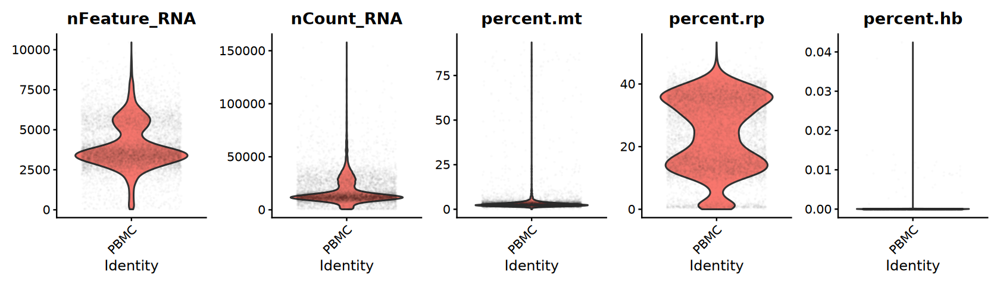

In [15]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

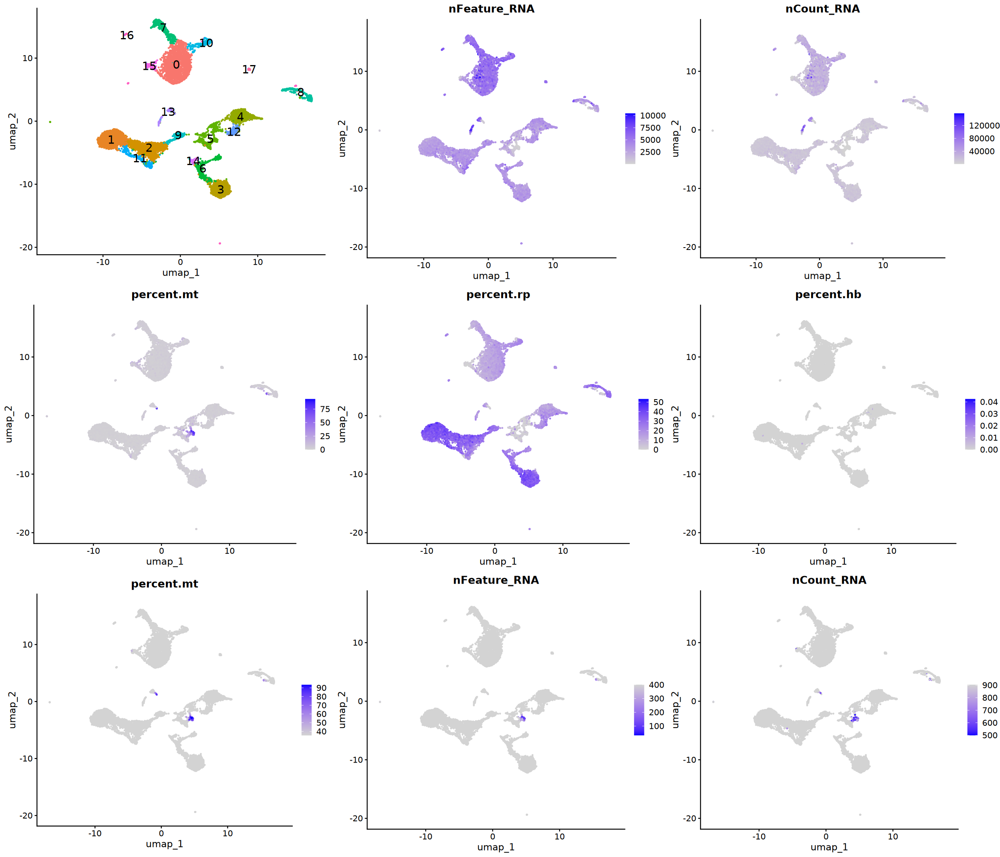

In [16]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", features = "percent.mt",
    min.cutoff = "q99", order = TRUE)
p4 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [17]:
source("R/calculate_mad_threshold.R")

In [18]:
cat(sprintf("Counts: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "lower")))

cat(sprintf("Features: Lower: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "lower")))

cat(sprintf("Mitochondrial: Upper: %d\n", calculate_mad_threshold(
    sc.temp$percent.mt, nmads = 3, sides = "upper")))

Counts: Lower: 3336
Features: Lower: 1499
Mitochondrial: Upper: 8


## 3). Filtering Low-quality Cells

In [19]:
scrna <- subset(
    scrna, 
    subset = nFeature_RNA > 500 & percent.mt < 10)
scrna

An object of class Seurat 
26151 features across 9507 samples within 2 assays 
Active assay: RNA (26141 features, 0 variable features)
 1 layer present: counts
 1 other assay present: ADT

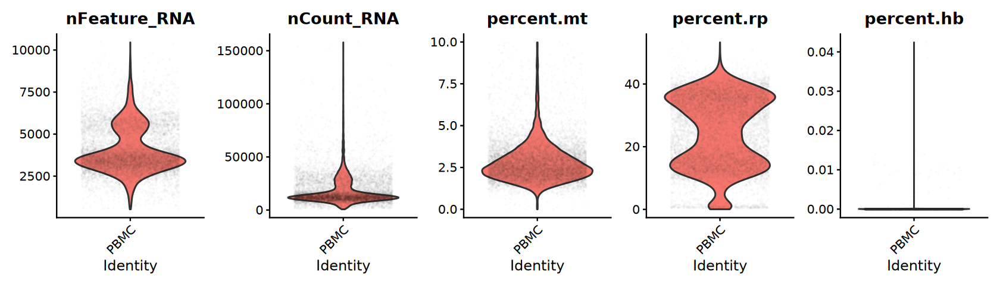

In [20]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(scrna, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

## 4). Doublet Detection

### a). [DoubletFinder](https://github.com/chris-mcginnis-ucsf/DoubletFinder)

In [21]:
source("R/run_DoubletFinder.R")

In [22]:
scrna <- run_DoubletFinder(
    scrna, ndim = 20, clusters = "seurat_clusters", 
    multiplet.rate = 0.008, seed = 123)

[1] "Creating 3169 artificial doublets..."
[1] "Classifying doublets.."


DoubletFinder completed: pN = 0.25, pK = 0.04, nExp_adj = 641



In [23]:
table(scrna$DoubletFinder.class)


Singlet Doublet 
   8866     641 

### b). [scDblFinder](https://github.com/plger/scDblFinder)

In [24]:
suppressPackageStartupMessages(library(scDblFinder))

In [25]:
set.seed(123)
sce <- run_seurat_pipeline(scrna, ndim = 20) |>
    as.SingleCellExperiment() |>
    scDblFinder(clusters = "seurat_clusters", verbose = FALSE)

In [26]:
scrna$scDblFinder.score <- colData(sce)$scDblFinder.score
scrna$scDblFinder.class <- colData(sce)$scDblFinder.class

In [27]:
table(scrna$scDblFinder.class)


singlet doublet 
   8988     519 

### Filtering Doublets

In [28]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

In [29]:
table(scDblFinder = sc.temp$scDblFinder.class, 
      DoubletFinder = sc.temp$DoubletFinder.class)

           DoubletFinder
scDblFinder Singlet Doublet
    singlet    8564     424
    doublet     302     217

In [30]:
sc.temp$isDoublet <- apply(
    sc.temp@meta.data[, c(
        "scDblFinder.class", "DoubletFinder.class")],
    1, function(x) paste(x, collapse = "_")
    ) |> as.factor()

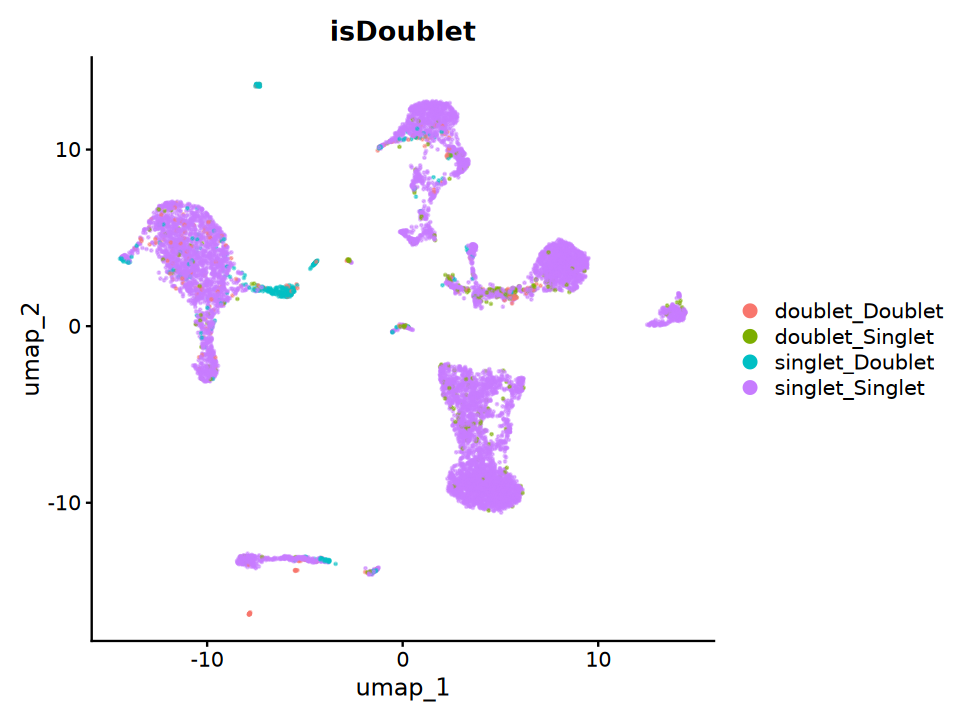

In [31]:
options(repr.plot.width = 8, repr.plot.height = 6)
DimPlot(sc.temp, reduction = "umap",
        group.by = "isDoublet", 
        pt.size = 0.1, alpha = 0.5)

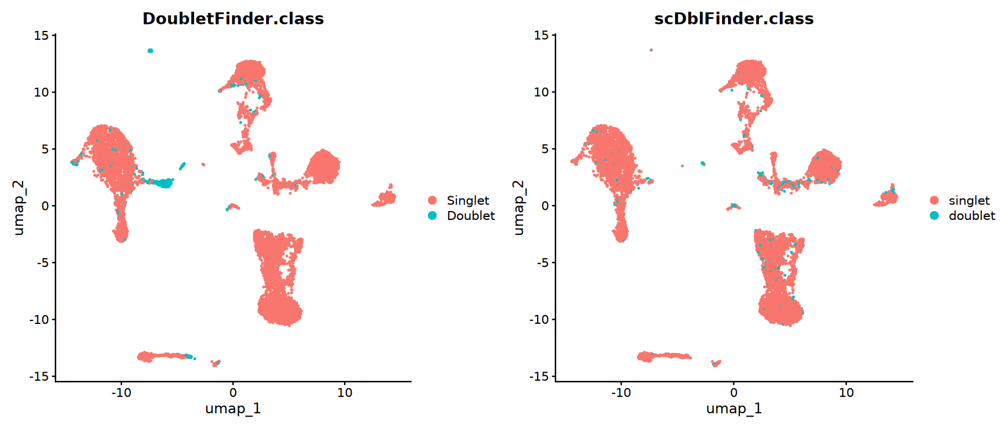

In [32]:
p1 <- DimPlot(
    subset(sc.temp, subset = scDblFinder.class == "singlet"),
    reduction = "umap", group.by = "DoubletFinder.class")
p2 <- DimPlot(
    subset(sc.temp, subset = DoubletFinder.class == "Singlet"), 
    reduction = "umap", group.by = "scDblFinder.class")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [33]:
sc.temp <- subset(
    sc.temp, 
    subset = DoubletFinder.class == "Singlet" |
        scDblFinder.class == "singlet")
sc.temp

An object of class Seurat 
26151 features across 9290 samples within 2 assays 
Active assay: RNA (26141 features, 2000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ADT
 3 dimensional reductions calculated: pca, umap, tsne

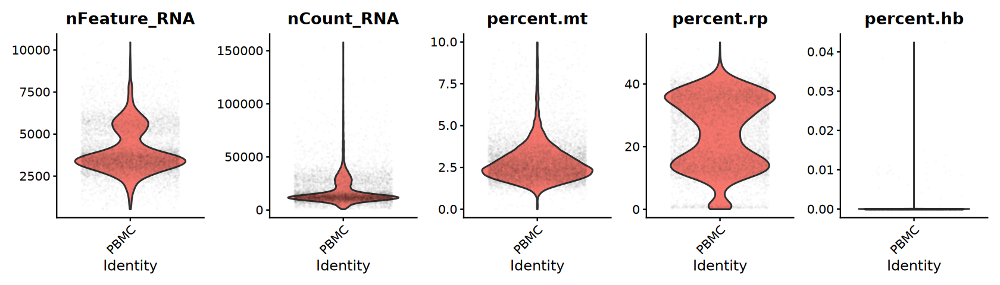

In [34]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(sc.temp, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

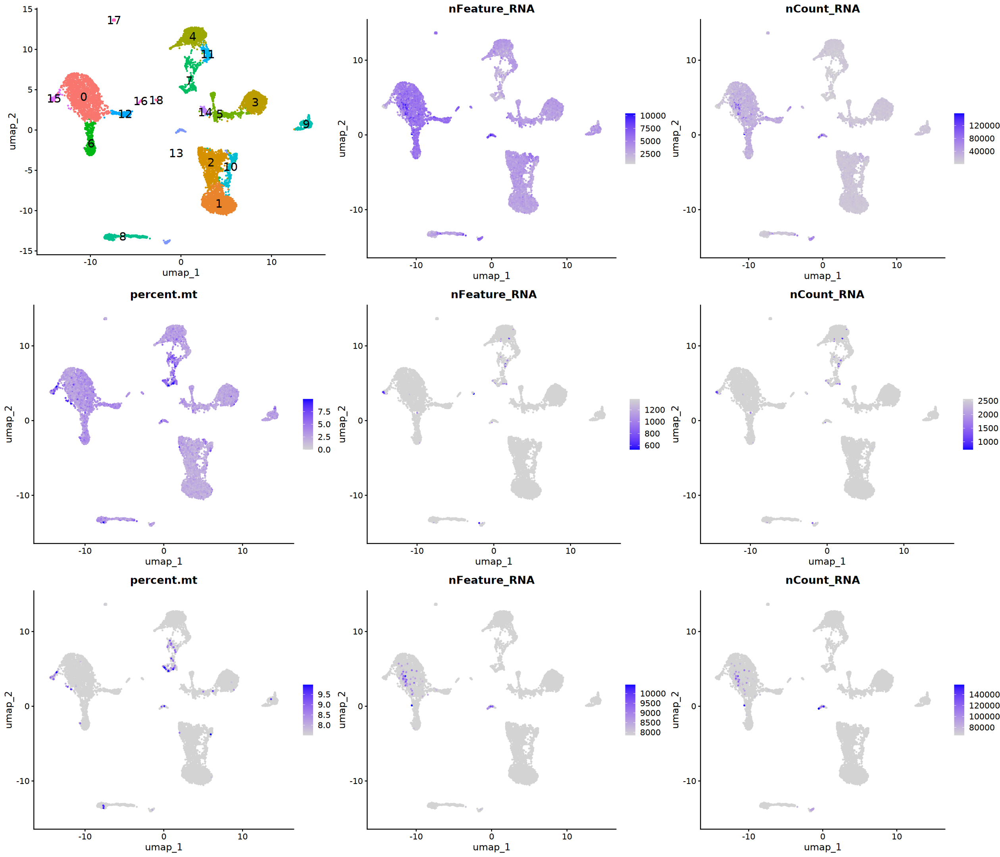

In [35]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt"))
p3 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"),
    max.cutoff = "q1", cols = c("blue", "lightgrey"))
p4 <- FeaturePlot(
    sc.temp, reduction = "umap",
    features = c("percent.mt", "nFeature_RNA", "nCount_RNA"),
    min.cutoff = "q99", order = TRUE, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3, byrow = TRUE)

In [36]:
summary(sc.temp@meta.data[, c("nFeature_RNA", "nCount_RNA", "percent.mt")])

  nFeature_RNA     nCount_RNA       percent.mt   
 Min.   :  528   Min.   :   715   Min.   :0.000  
 1st Qu.: 3091   1st Qu.: 10386   1st Qu.:2.034  
 Median : 3599   Median : 13140   Median :2.559  
 Mean   : 3958   Mean   : 17369   Mean   :2.793  
 3rd Qu.: 4837   3rd Qu.: 20604   3rd Qu.:3.263  
 Max.   :10455   Max.   :157836   Max.   :9.974  

In [37]:
cat(sprintf("Counts: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nCount_RNA, nmads = 3, sides = "upper")))

cat(sprintf("Features: Upper: %d\n", calculate_mad_threshold(
    sc.temp$nFeature_RNA, nmads = 3, sides = "upper")))

Counts: Upper: 47589
Features: Upper: 8213


In [38]:
scrna <- scrna |>
    subset(
        subset = DoubletFinder.class == "Singlet" |
            scDblFinder.class == "singlet") |>
    subset(
        subset = nCount_RNA < 50000 & 
            percent.mt < 10 & percent.hb < 1)
scrna

An object of class Seurat 
26151 features across 9061 samples within 2 assays 
Active assay: RNA (26141 features, 0 variable features)
 1 layer present: counts
 1 other assay present: ADT

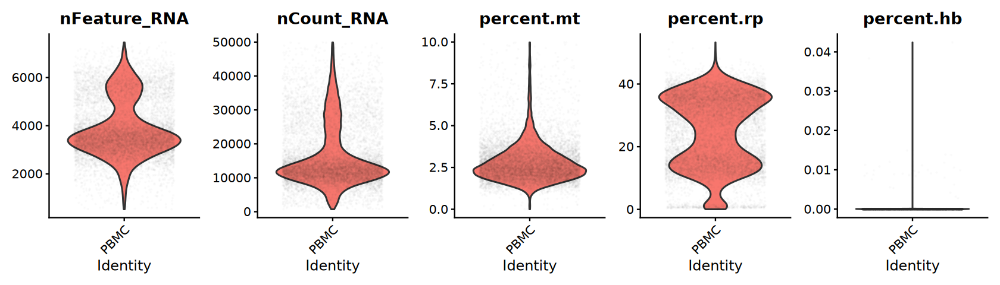

In [39]:
options(repr.plot.width = 14, repr.plot.height = 4)
VlnPlot(scrna, layer = "counts", group.by = "orig.ident",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt",
                     "percent.rp", "percent.hb"), 
        pt.size = 0.01, alpha = 0.01, ncol = 5) & NoLegend()

## 5). Evaluating Noise

### a). Cell cycle effect

In [40]:
str(cc.genes)

List of 2
 $ s.genes  : chr [1:43] "MCM5" "PCNA" "TYMS" "FEN1" ...
 $ g2m.genes: chr [1:54] "HMGB2" "CDK1" "NUSAP1" "UBE2C" ...


In [41]:
scrna <- NormalizeData(scrna, verbose = FALSE) |> 
    CellCycleScoring(s.features = cc.genes$s.genes,
                     g2m.features = cc.genes$g2m.genes)

Warning message:
“The following features are not present in the object: MLF1IP, not searching for symbol synonyms”
Warning message:
“The following features are not present in the object: FAM64A, HN1, not searching for symbol synonyms”


### b). Cell dissociation effect

In [42]:
dissociation_genes <- readLines(
    "~/data1/single_cell_dataset/reference_infomation/dissociation_genes.txt")
str(dissociation_genes)

 chr [1:140] "Actg1" "Btg1" "Cxcl1" "Dnajb4" "Errfi1" "H3f3b" "Hspb1" ...


In [43]:
scrna <- AddModuleScore(
    scrna, name = "Dissociation.Score", 
    features = list(
        dissociationGenes = toupper(dissociation_genes)))
# rename
scrna@meta.data <- scrna@meta.data |> 
    dplyr::rename("Dis.Score" = "Dissociation.Score1")

Warning message:
“The following features are not present in the object: H3F3B, ANKRD1, CYR61, FAM132B, MT1, DCN, MT2, CCRN4L, KCNE4, not searching for symbol synonyms”


# 3. Initial Assessment

In [44]:
sc.temp <- run_seurat_pipeline(scrna, ndim = 20)

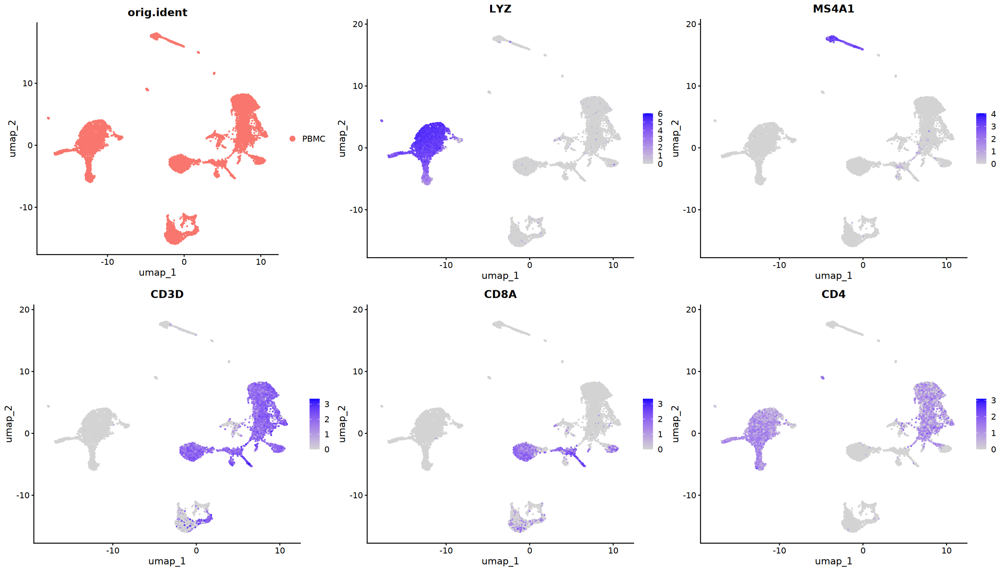

In [45]:
geneset <- c("LYZ", "MS4A1", "CD3D", "CD8A", "CD4")
p1 <- DimPlot(
    sc.temp, reduction = "umap", group.by = "orig.ident")
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", features = geneset,
    combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

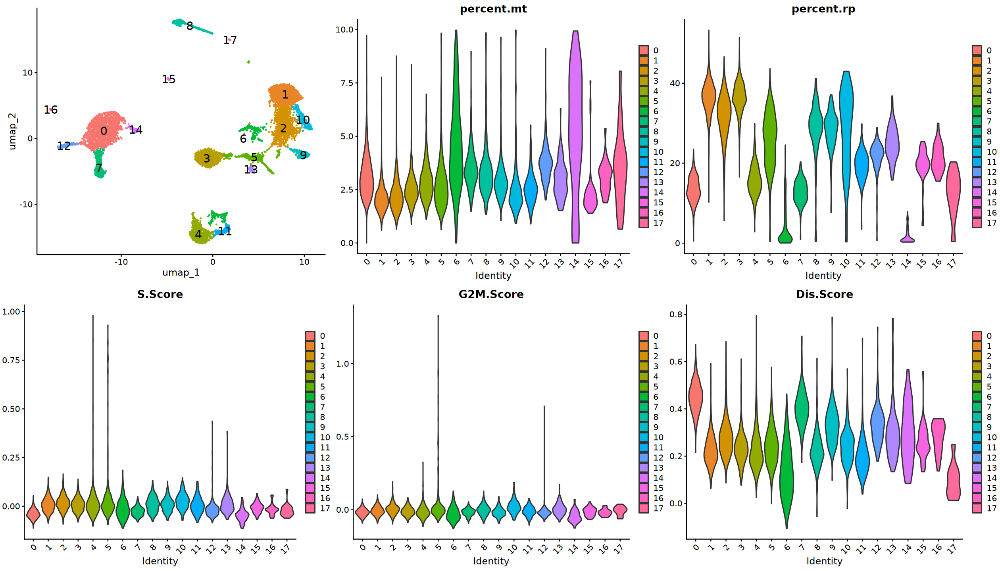

In [46]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", label = TRUE, 
    label.size = 6) & NoLegend()
p2 <- VlnPlot(
    sc.temp, features = c("percent.mt", "percent.rp"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    sc.temp, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

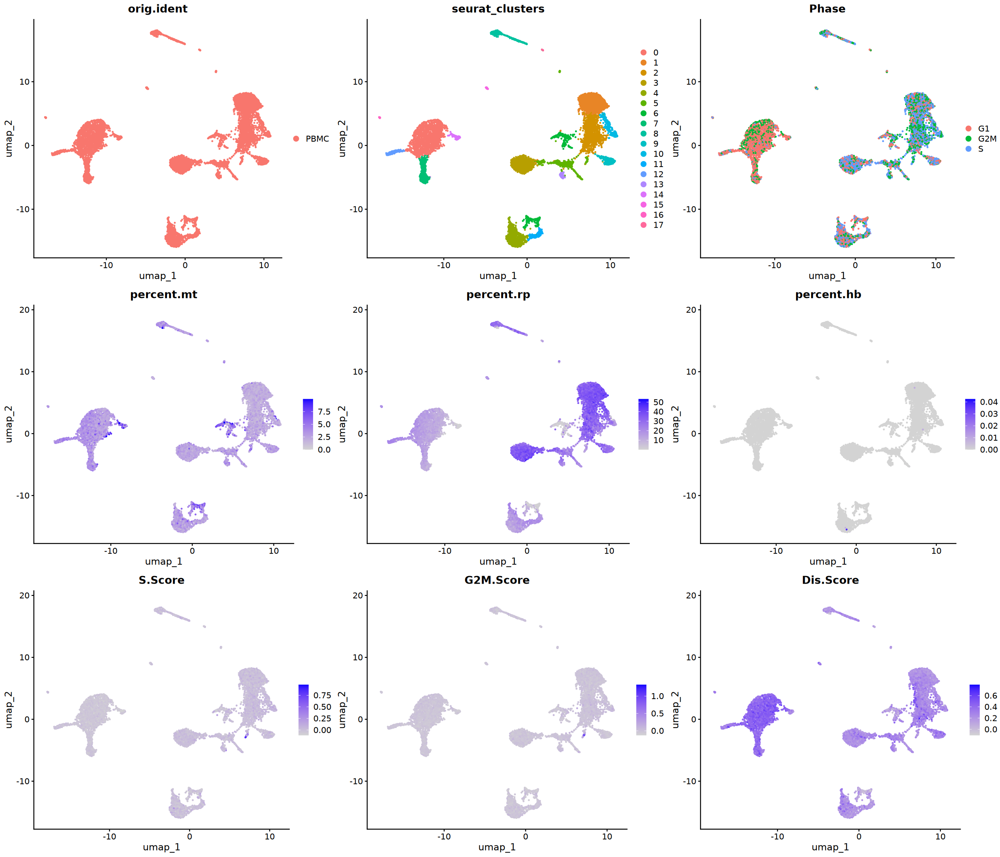

In [47]:
p1 <- DimPlot(
    sc.temp, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- FeaturePlot(
    sc.temp, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = c(p1, p2), ncol = 3)

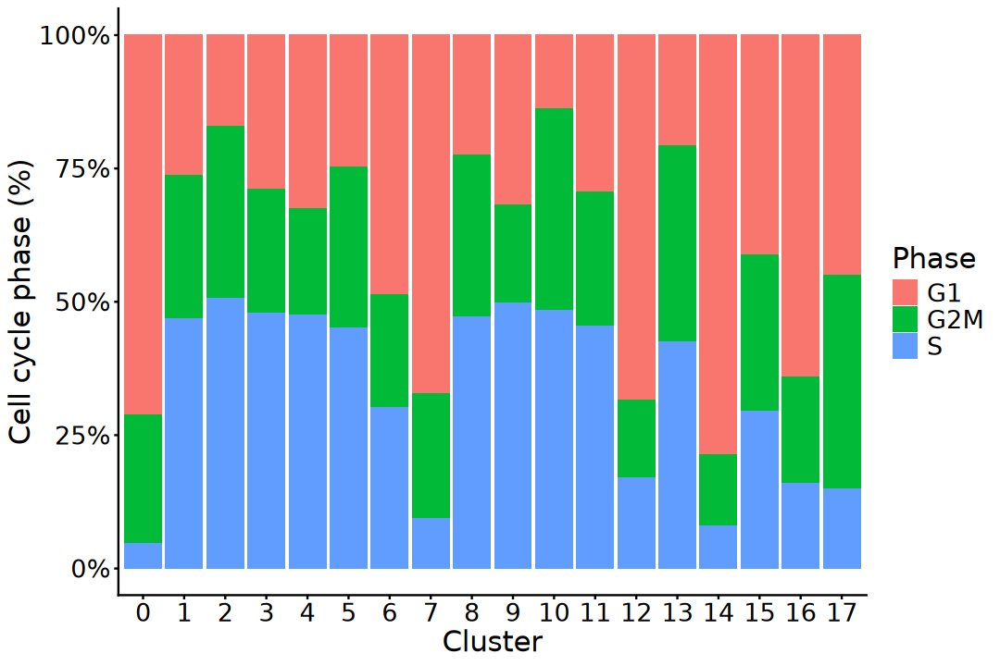

In [48]:
options(repr.plot.width = 9, repr.plot.height = 6)
table(sc.temp$seurat_clusters, sc.temp$Phase) |> 
    as.data.frame() |>
    ggplot(aes(x = Var1, y = Freq, fill = Var2)) +
        geom_bar(stat = "identity", position = "fill") +
        scale_y_continuous(labels = scales::percent_format()) +
        labs(x = "Cluster", y = "Cell cycle phase (%)", 
             fill = "Phase") +
        theme_classic() + 
        theme(axis.title = element_text(size = 18),
              axis.text = element_text(size = 16),
              legend.title = element_text(size = 18),
              legend.text = element_text(size = 16))

In [49]:
pca <- Embeddings(sc.temp, "pca")[, 1:10]

vars <- c("nCount_RNA", "percent.mt", "percent.rp", "percent.hb", 
          "S.Score", "G2M.Score", "Dis.Score")

cors <- sapply(vars, function(v) {
    apply(pca, 2, cor, y = sc.temp[[v]], method = "pearson")
}) |> t()

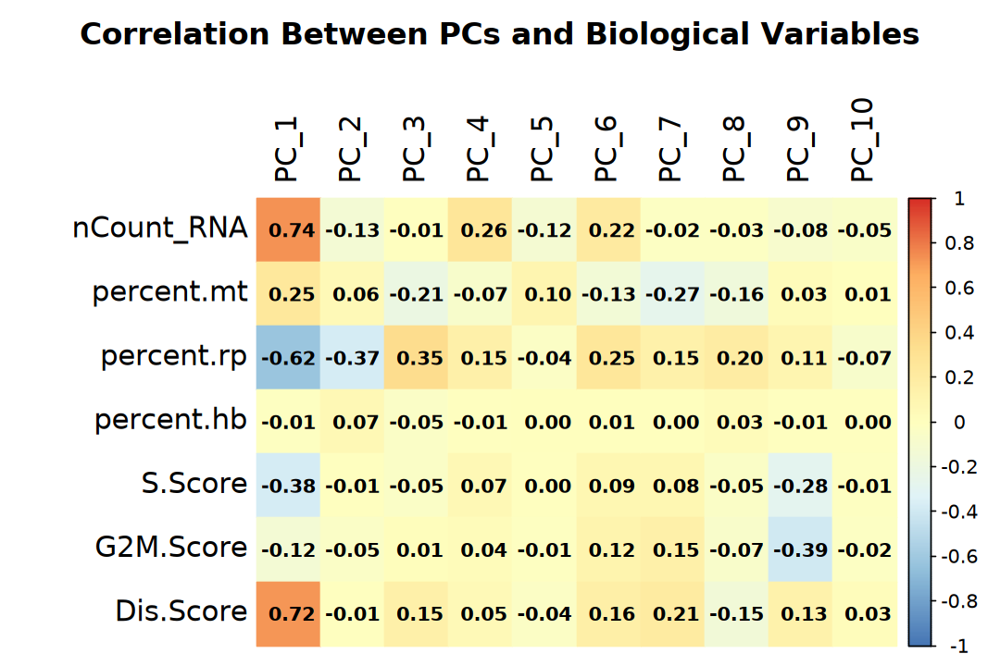

In [50]:
options(repr.plot.width = 9, repr.plot.height = 6)

gradient_colors <- colorRampPalette(
    c("#4575B4", "#91BFDB", "#E0F3F8", "#FFFFBF", 
      "#FEE090", "#FDAE61", "#D73027"))(200)

corrplot::corrplot(cors, method = "color",
                   col = gradient_colors, cl.cex = 1, 
                   col.lim = c(-1, 1),
                   title = "Correlation Between PCs and Biological Variables",
                   cex.main = 1.6, col.main = "black",
                   tl.col = "black", tl.cex = 1.5,
                   addCoef.col = "black", number.cex = 1, 
                   is.corr = FALSE, mar = c(0, 0, 3, 0))

# 4. Normalization

In [51]:
# Normalizate: log1p(counts per 10k)
scrna <- NormalizeData(scrna, verbose = FALSE) |>
    FindVariableFeatures(nfeatures = 3000, verbose = FALSE) |>
    ScaleData(vars.to.regress = "percent.mt", verbose = FALSE)

# 5. Linear Dimensionality Reduction

In [52]:
scrna <- RunPCA(scrna, npcs = 50, verbose = FALSE)

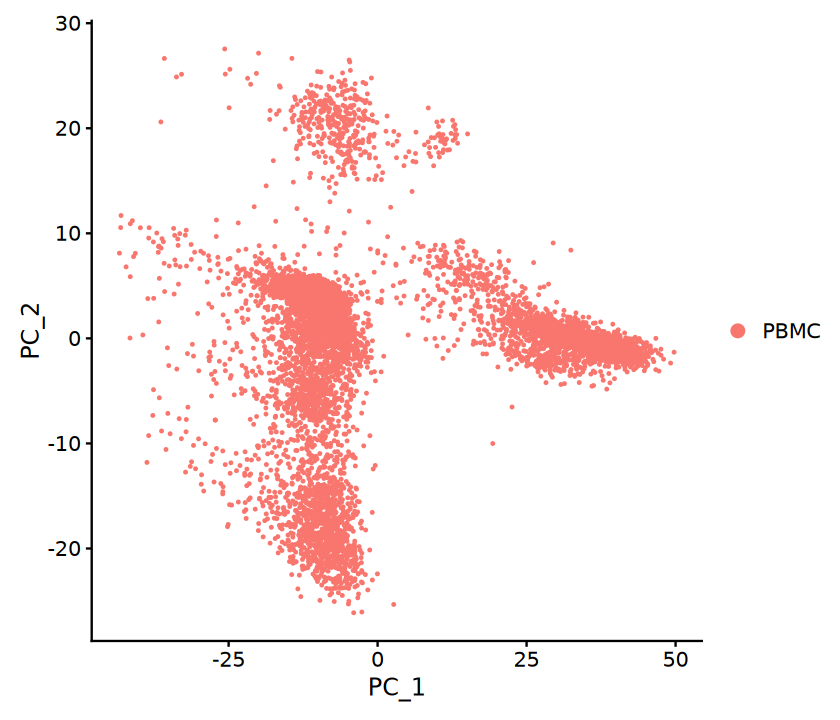

In [53]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(scrna, reduction = "pca")

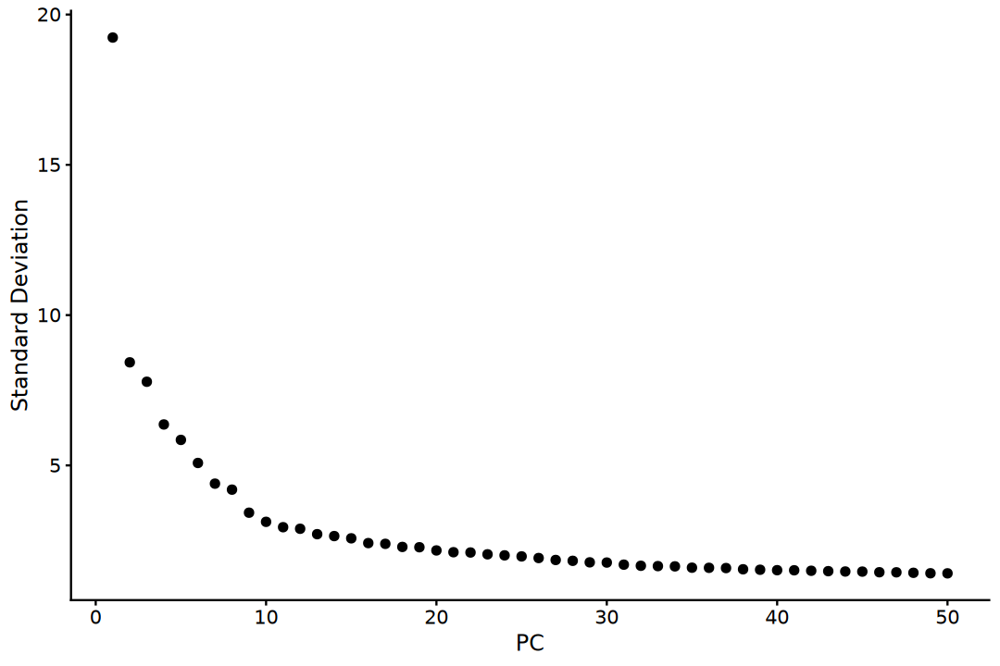

In [54]:
# Elbow plot
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(scrna, ndims = 50)

In [55]:
# Estimating PCA dimensionality
pca_var <- scrna@reductions$pca@stdev ^ 2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 21


In [56]:
source("R/compare_npcs_clustering.R")

In [57]:
plots <- compare_npcs_clustering(
    scrna, reduction = "pca", method = "umap")

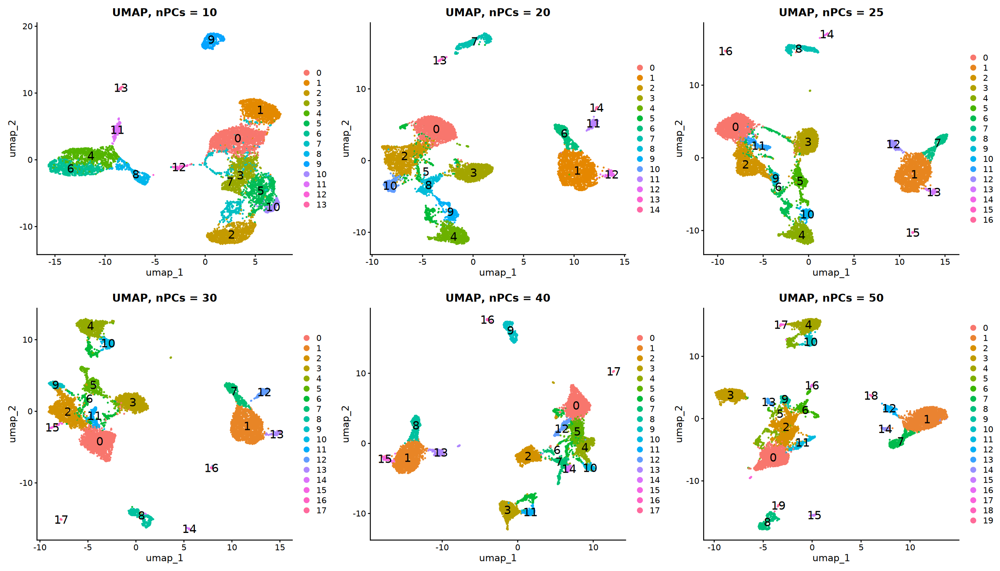

In [58]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = plots, ncol = 3)

In [59]:
nPCs <- 30

# 6. Integration (Skip)

# 7. Neighborhood Graph Construction

In [60]:
scrna <- FindNeighbors(
    scrna, k.param = 20, reduction = "pca", dims = 1:nPCs,
    verbose = FALSE)

# 8. Non-linear Dimensionality Reduction

In [61]:
scrna <- RunUMAP(
    scrna, reduction = "pca", dims = 1:nPCs, verbose = FALSE)

In [62]:
scrna <- RunTSNE(
    scrna, reduction = "pca", dims = 1:nPCs, verbose = FALSE)

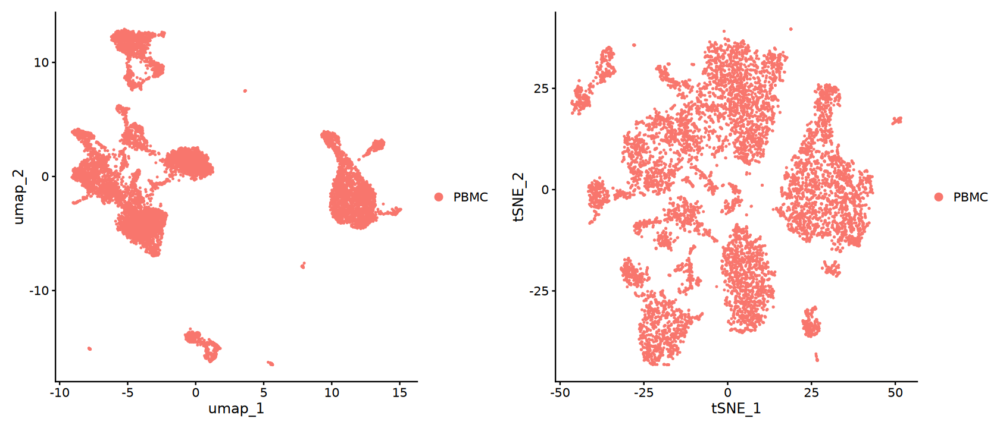

In [63]:
p1 <- DimPlot(scrna, reduction = "umap")
p2 <- DimPlot(scrna, reduction = "tsne")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

# 9. Clustering

In [64]:
source("R/scan_clustering_resolution.R")

In [65]:
cluster_list <- scan_clustering_resolution(
    scrna, reduction = "pca", dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1), assess = FALSE)

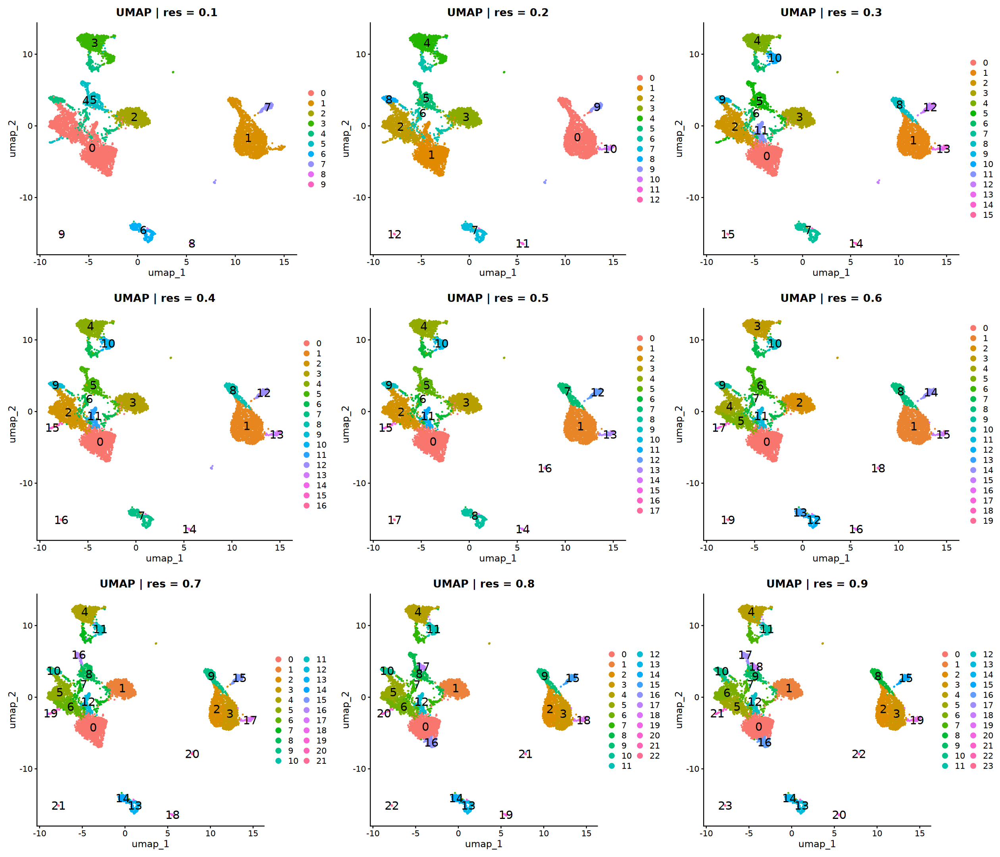

In [66]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$umap, ncol = 3)

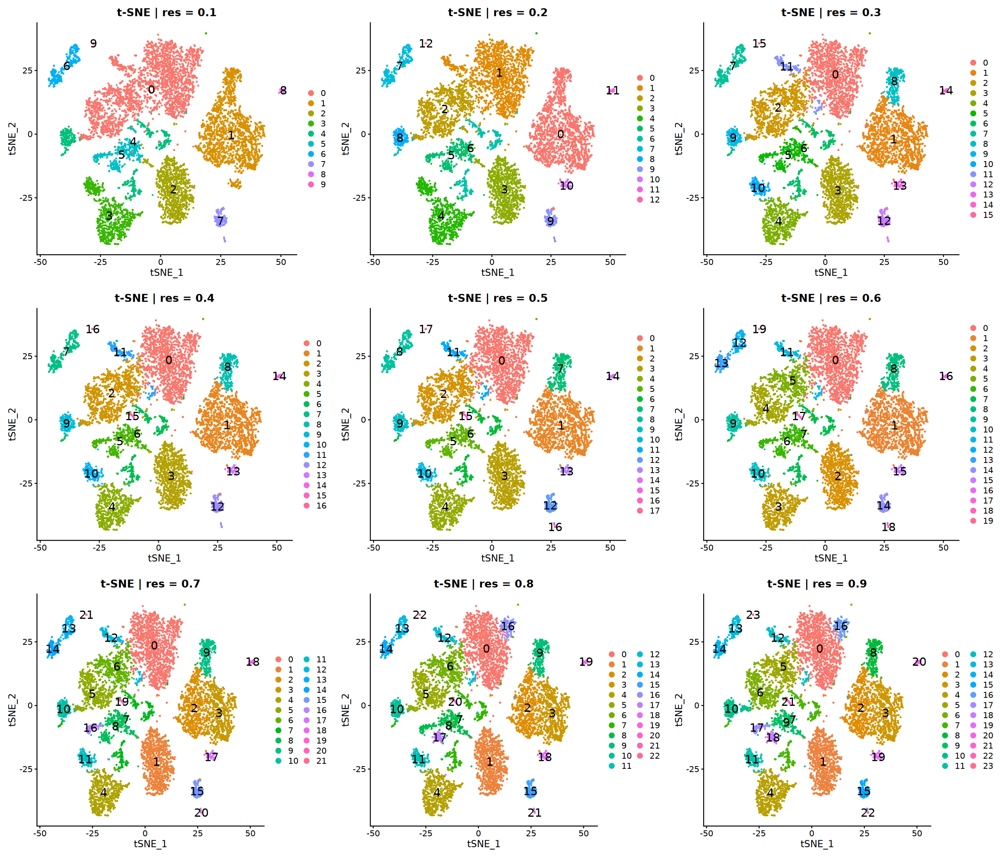

In [67]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$tsne, ncol = 3)

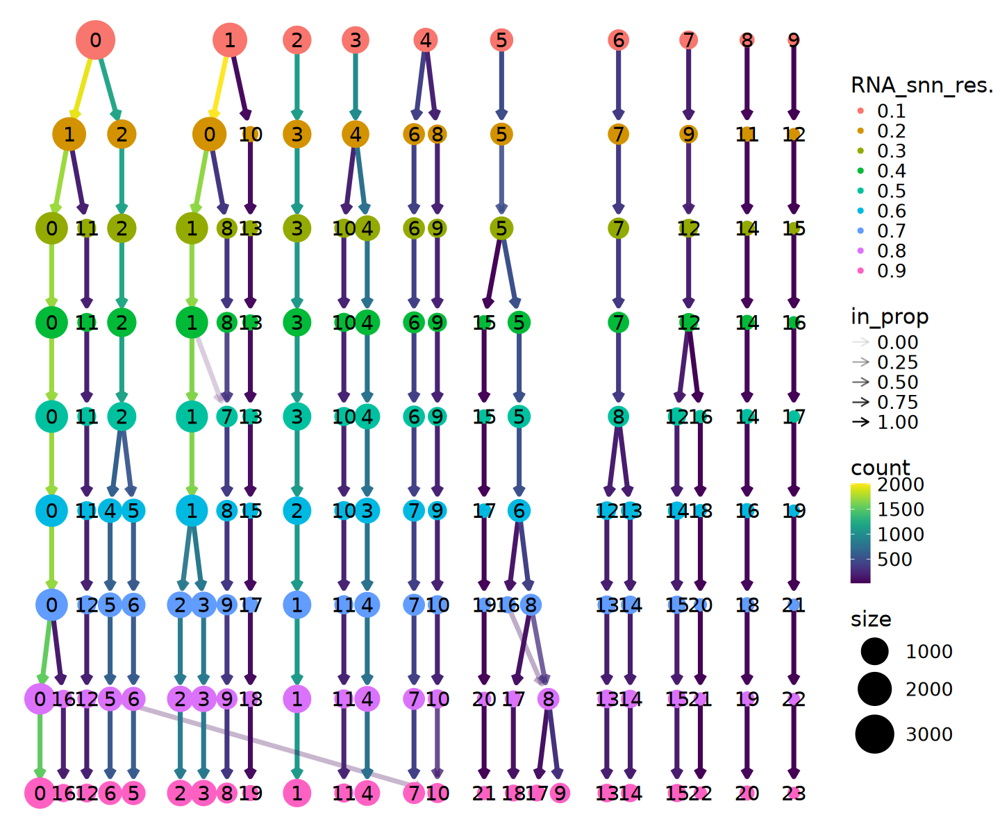

In [68]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$clustree

In [69]:
scrna <- FindClusters(scrna, resolution = 0.5, verbose = FALSE)

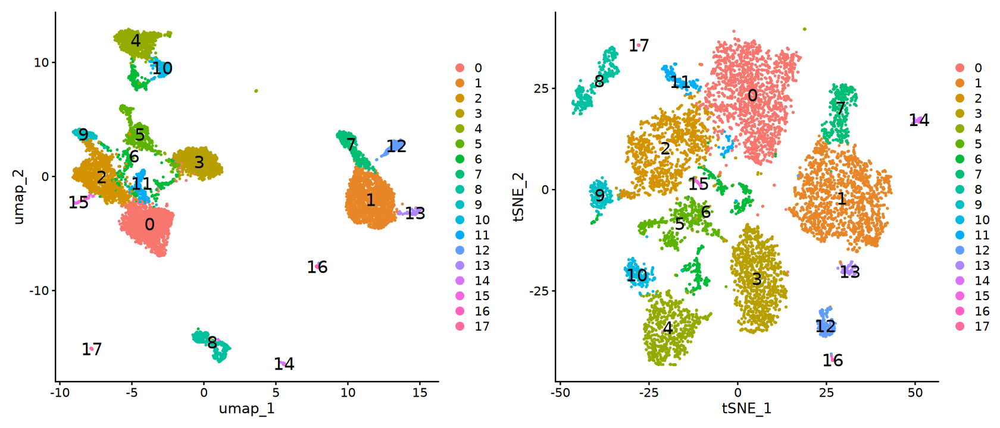

In [76]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6, repel = FALSE)
p2 <- DimPlot(
    scrna, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

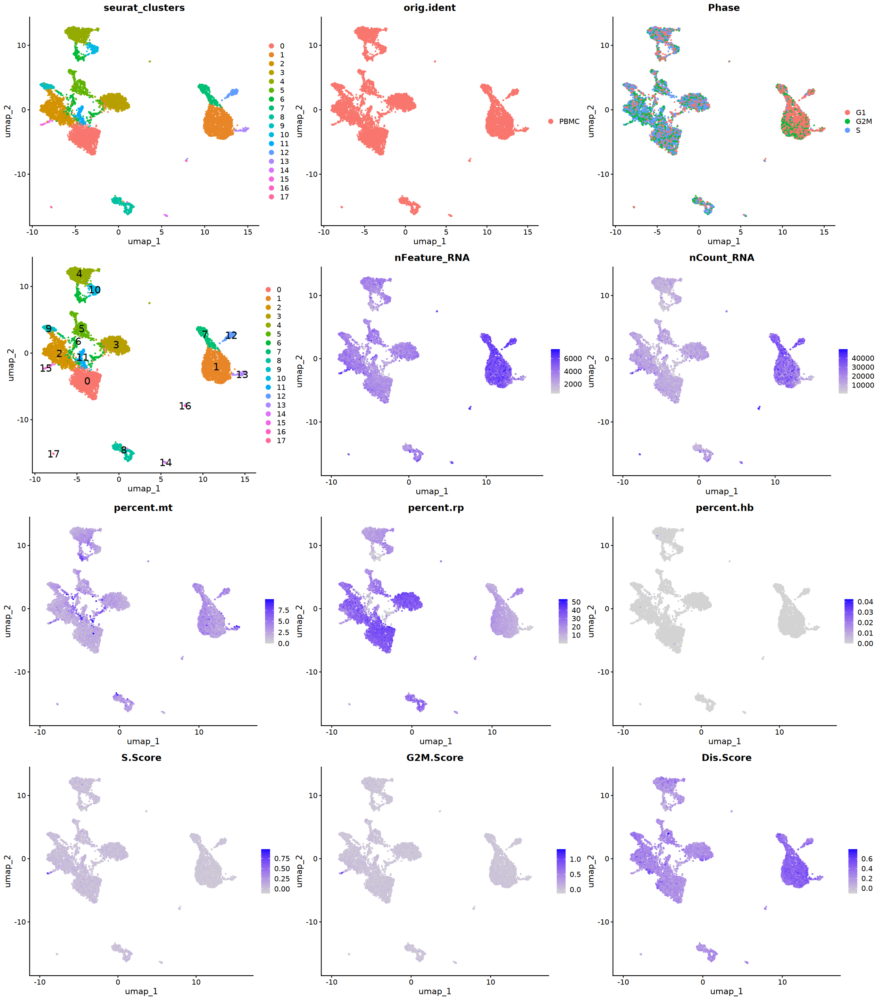

In [77]:
p1 <- DimPlot(
    scrna, reduction = "umap", combine = FALSE,
    group.by = c("seurat_clusters", "orig.ident", "Phase"))
p2 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6)
p3 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [78]:
scrna

An object of class Seurat 
26151 features across 9061 samples within 2 assays 
Active assay: RNA (26141 features, 3000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ADT
 3 dimensional reductions calculated: pca, umap, tsne

# 10. Cluster Biomarkers

In [79]:
sc.markers <- FindAllMarkers(
    scrna, logfc.threshold = log2(1.2), min.pct = 0.25, 
    only.pos = TRUE, verbose = FALSE)

In [80]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [81]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
length(gene),144,2977,179,192,353,144,33,2730,382,277,321,122,2294,656,1530,632,1009,280


In [82]:
top10 <- sc.markers.filt |> group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

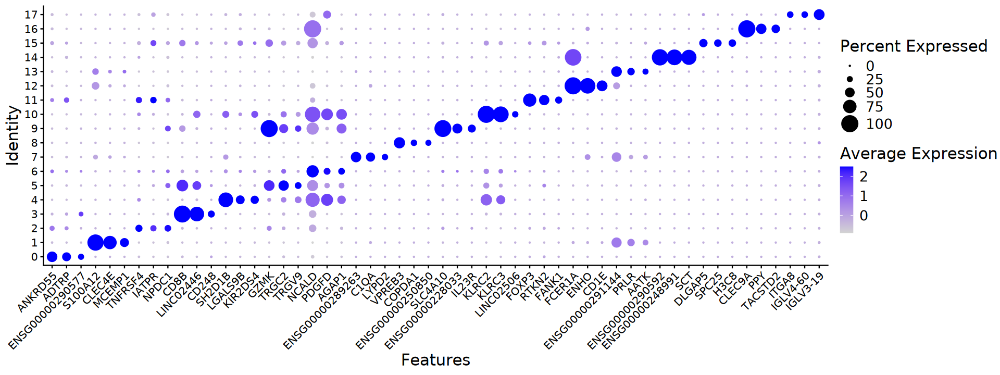

In [83]:
options(repr.plot.width = 16, repr.plot.height = 6)
DotPlot(scrna, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [84]:
# plot_dir <- file.path(
#     data_dir, "visualization", "p7.1_cluster_top10_genes")

# if (!dir.exists(plot_dir)) {
#     dir.create(plot_dir, recursive = TRUE)
# }

In [85]:
# for (index in seq(1:length(top10$gene))) {
#     p1 <- VlnPlot(scrna, features = top10$gene[index])
#     p2 <- FeaturePlot(
#         scrna, reduction = "umap", features = top10$gene[index])
#     p3 <- FeaturePlot(
#         scrna, reduction = "tsne", features = top10$gene[index])
#     pg <- plot_grid(p1, plot_grid(p2, p3, ncol = 2), ncol = 1)
    
#     file.path(plot_dir, paste0(
#         "cluster_", top10$cluster[index], "_", top10$gene[index], ".png")) |>
#         ggsave(plot = pg, width = 9, height = 8)
# }

In [86]:
# options(repr.plot.width = 18, repr.plot.height = 8)
# DoHeatmap(scrna, slot = "scale.data", 
#           features = top3$gene, size = 8) +
#     # scale_fill_gradientn(colors = PurpleAndYellow()) +
#     theme(axis.text = element_text(size = 12),
#           legend.title = element_text(size = 18), 
#           legend.text = element_text(size = 16))

# 11. VDJ

In [87]:
suppressPackageStartupMessages(library(scRepertoire))

In [88]:
tcr <-  file.path(data_dir, "outs", "per_sample_outs", "Donor", 
                  "vdj_t", "filtered_contig_annotations.csv") |> 
    read.csv(header = TRUE)
head(tcr)

,barcode,is_cell,contig_id,high_confidence,length,chain,v_gene,d_gene,j_gene,c_gene,⋯,fwr3_nt,cdr3,cdr3_nt,fwr4,fwr4_nt,reads,umis,raw_clonotype_id,raw_consensus_id,exact_subclonotype_id
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<int>
1,AAACCAAAGCGTTACA-1,true,AAACCAAAGCGTTACA-1_contig_1,true,541,TRA,TRAV12-2,,TRAJ26,TRAC,⋯,AAAGAAGATGGAAGGTTTACAGCACAGCTCAATAAAGCCAGCCAGTATGTTTCTCTGCTCATCAGAGACTCCCAGCCCAGTGATTCAGCCACCTACCTC,CAVDNYGQNFVF,TGTGCCGTAGATAACTATGGTCAGAATTTTGTCTTT,GPGTRLSVLP,GGTCCCGGAACCAGATTGTCCGTGCTGCCCT,3646,11,sample0_clonotype3882,sample0_clonotype3882_consensus_2,1
2,AAACCAAAGCGTTACA-1,true,AAACCAAAGCGTTACA-1_contig_2,true,495,TRB,TRBV25-1,TRBD1,TRBJ2-7,TRBC2,⋯,ACAGAGAAGGGAGATCTTTCCTCTGAGTCAACAGTCTCCAGAATAAGGACGGAGCATTTTCCCCTGACCCTGGAGTCTGCCAGGCCCTCACATACCTCTCAGTACCTC,CASSDTTRTGGFYEQYF,TGTGCCAGCAGTGATACCACTCGGACAGGGGGGTTCTACGAGCAGTACTTC,GPGTRLTVT,GGGCCGGGCACCAGGCTCACGGTCACAG,8743,32,sample0_clonotype3882,sample0_clonotype3882_consensus_1,1
3,AAACCAAAGCGTTACA-1,true,AAACCAAAGCGTTACA-1_contig_3,true,511,TRA,TRAV1-2,,TRAJ26,TRAC,⋯,GAGGAGAAAGGTCGTTTTTCTTCATTCCTTAGTCGGTCTAAAGGGTACAGTTACCTCCTTTTGAAGGAGCTCCAGATGAAAGACTCTGCCTCTTACCTC,CAVREKGEGQNFVF,TGTGCTGTGAGAGAGAAGGGTGAAGGTCAGAATTTTGTCTTT,GPGTRLSVLP,GGTCCCGGAACCAGATTGTCCGTGCTGCCCT,2982,12,sample0_clonotype3882,sample0_clonotype3882_consensus_3,1
4,AAACCAAAGGTATCCA-1,true,AAACCAAAGGTATCCA-1_contig_1,true,513,TRB,TRBV5-1,,TRBJ2-2,TRBC2,⋯,AGAAACAAAGGAAACTTCCCTGGTCGATTCTCAGGGCGCCAGTTCTCTAACTCTCGCTCTGAGATGAATGTGAGCACCTTGGAGCTGGGGGACTCGGCCCTTTATCTT,CASSLSSGANTGELFF,TGCGCCAGCAGCTTGAGCTCGGGGGCCAATACCGGGGAGCTGTTTTTT,GEGSRLTVL,GGAGAAGGCTCTAGGCTGACCGTACTGG,12794,45,sample0_clonotype3611,sample0_clonotype3611_consensus_1,1
5,AAACCAAAGGTATCCA-1,true,AAACCAAAGGTATCCA-1_contig_2,true,498,TRA,TRAV12-3,,TRAJ30,TRAC,⋯,AAAGAAGATGGAAGGTTTACAGCACAGGTCGATAAATCCAGCAAGTATATCTCCTTGTTCATCAGAGACTCACAGCCCAGTGATTCAGCCACCTACCTC,CAMSENRDDKIIF,TGTGCAATGAGCGAGAACAGAGATGACAAGATCATCTTT,GKGTRLHILP,GGAAAAGGGACACGACTTCATATTCTCCCCA,5894,15,sample0_clonotype3611,sample0_clonotype3611_consensus_2,1
6,AAACCAGCAATAGCAG-1,true,AAACCAGCAATAGCAG-1_contig_1,true,516,TRB,TRBV12-5,TRBD1,TRBJ1-1,TRBC1,⋯,CTAGATGATTCGGGGATGCCGAAGGATCGATTCTCAGCAGAGATGCCTGATGCAACTTTAGCCACTCTGAAGATCCAGCCCTCAGAACCCAGGGACTCAGCTGTGTATTTT,CASGLAKGATEAFF,TGTGCTAGTGGTTTGGCTAAGGGGGCCACTGAAGCTTTCTTT,GQGTRLTVV,GGACAAGGCACCAGACTCACAGTTGTAG,16267,52,sample0_clonotype2461,sample0_clonotype2461_consensus_1,1


In [89]:
bcr <-  file.path(data_dir, "outs", "per_sample_outs", "Donor", 
                  "vdj_b", "filtered_contig_annotations.csv") |> 
    read.csv(header = TRUE)
head(bcr)

,barcode,is_cell,contig_id,high_confidence,length,chain,v_gene,d_gene,j_gene,c_gene,⋯,fwr3_nt,cdr3,cdr3_nt,fwr4,fwr4_nt,reads,umis,raw_clonotype_id,raw_consensus_id,exact_subclonotype_id
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<int>
1,AAAGCATCAGCTCTAG-1,true,AAAGCATCAGCTCTAG-1_contig_1,true,551,IGK,IGKV1-39,,IGKJ3,IGKC,⋯,GGGGTCCCATCAAGGTTCAGTGGCAGTGGATCTGGGACAGACTTCACTCTCACCATCAGCAGTCTGCAACCTGAAGATTTTGCAACTTACTAC,CQQSYSTPATF,TGTCAACAGAGTTACAGTACCCCTGCCACCTTC,GPGTKVEIK,GGCCCTGGGACCAAAGTGGAAATCAAAC,3027,80,sample0_clonotype69,sample0_clonotype69_consensus_2,1
2,AAAGCATCAGCTCTAG-1,true,AAAGCATCAGCTCTAG-1_contig_2,true,562,IGH,IGHV3-23,,IGHJ4,IGHM,⋯,ACATCCTTCGCAGACTCCGTGAAGGGCCGGTTCACCATCTCCAGAGACAATTCCAGGAACACGCTGTATCTGCAAATGAACAGCCTGAGAGCCGAGGACACGGCCGTATATTAC,CAKDRSVSGFDYW,TGTGCGAAAGATCGGTCAGTGTCTGGCTTTGACTACTGG,GQGALVTVSS,GGCCAGGGAGCCCTGGTCACCGTCTCCTCAG,1582,41,sample0_clonotype69,sample0_clonotype69_consensus_1,1
3,AAATCACTCCGATAGC-1,true,AAATCACTCCGATAGC-1_contig_1,true,566,IGH,IGHV3-72,,IGHJ3,IGHM,⋯,ACAGAATACGCCGCGTCTGTGAAAGGCAGATTCACCATCTCAAGAGATGATTCAAAGAACTCACTGTATCTGCAAATGAACAGCCTGAAAACCGAGGACACGGCCGTGTATTAC,CARTMMAAFDIW,TGTGCTAGAACTATGATGGCTGCTTTTGATATCTGG,GQGTMVTVSS,GGCCAAGGGACAATGGTCACCGTCTCTTCAG,1909,54,sample0_clonotype98,sample0_clonotype98_consensus_1,1
4,AAATCACTCCGATAGC-1,true,AAATCACTCCGATAGC-1_contig_2,true,551,IGK,IGKV1-39,,IGKJ3,IGKC,⋯,GGGGTCCCATCAAGGTTCAGTGGCAGTGGATCTGGGACAGATTTCACTCTCACCATCAGCAGTCTGCAACCTGAAGATTTTGCAACTTACTAC,CQQSYSTPFTF,TGTCAACAGAGTTACAGTACCCCATTCACTTTC,GPGTKVDIK,GGCCCTGGGACCAAAGTGGATATCAAAC,2029,55,sample0_clonotype98,sample0_clonotype98_consensus_2,1
5,AAATGTCTCGTAAATC-1,true,AAATGTCTCGTAAATC-1_contig_1,true,643,IGH,IGHV4-39,,IGHJ3,IGHA1,⋯,ACCGAGTACAACCCGTCCCTCAAGAGTCGAGTGACCATCTCCGTAGACACGTCCAAGAATCAGATTTCCCTGACTCTGAACTCAGTTGTCGCCGCAGACACGGGTATATATTAT,CARLGARSVPVAGIIRGALDIW,TGTGCGAGACTTGGAGCAAGGAGTGTCCCAGTAGCTGGCATCATCCGCGGAGCTCTTGATATTTGG,GQGTAVTVSS,GGCCAAGGGACAGCGGTCACCGTCTCTTCGG,27733,5008,sample0_clonotype401,sample0_clonotype401_consensus_1,1
6,AAATGTCTCGTAAATC-1,true,AAATGTCTCGTAAATC-1_contig_2,true,554,IGK,IGKV1-39,,IGKJ4,IGKC,⋯,GGGGTCCCATCAAGGTTCAGTGGCAGTGGATCTGGGACAGATTTCAGTCTCACCATCAGCGGTCTGCAACCTGAAGATTTTGCAACTTATTAT,CQQSSTTPAVTF,TGTCAACAGAGTTCCACTACCCCCGCGGTCACTTTC,GGGTKVEIR,GGCGGAGGGACCAAGGTGGAGATCAGAC,45726,7710,sample0_clonotype401,sample0_clonotype401_consensus_2,1


## 1). Combining Contigs into Clones

In [90]:
tcr.comb <- combineTCR(tcr, samples = "PBMC")

In [92]:
bcr.comb <- combineBCR(bcr, samples = "PBMC", threshold = 0.85)

In [104]:
scrna <- combineExpression(
    list(TCR = tcr.comb, BCR = bcr.comb), scrna, 
    cloneCall = "gene+nt", group.by = "seurat_clusters", 
    proportion = TRUE)

ERROR: Error in .theCall(input.data, cloneCall): Check the clonal variable (cloneCall) being used in the function, it does not appear in the data provided.


# 12. Cell-type Annotation

## a). Automatic

In [107]:
suppressPackageStartupMessages(library(SingleR))

In [108]:
ref_pbmc <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "matrix", "RNA_3P", "RNA") |>
    Read10X()

In [109]:
ref_metadata <- file.path(
    "~/data1/single_cell_dataset/PBMCs/Hs_PBMC_GSE164378", 
    "GSE164378_sc.meta.data_3P.csv.gz") |>
    read.csv(header = TRUE, row.names = 1) |>
    select(celltype.l1, celltype.l2, celltype.l3)

In [110]:
ref_pbmc <- SingleCellExperiment(
    list(counts = ref_pbmc), 
    colData = ref_metadata)

ref_pbmc <- scuttle::logNormCounts(ref_pbmc)

ref_pbmc

class: SingleCellExperiment 
dim: 33538 161764 
metadata(0):
assays(2): counts logcounts
rownames(33538): MIR1302-2HG FAM138A ... AC213203.1 FAM231C
rowData names(0):
colnames(161764): L1_AAACCCAAGAAACTCA L1_AAACCCAAGACATACA ...
  E2L8_TTTGTTGGTTGGCTAT E2L8_TTTGTTGTCTCATGGA
colData names(4): celltype.l1 celltype.l2 celltype.l3 sizeFactor
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):

In [111]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l1, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

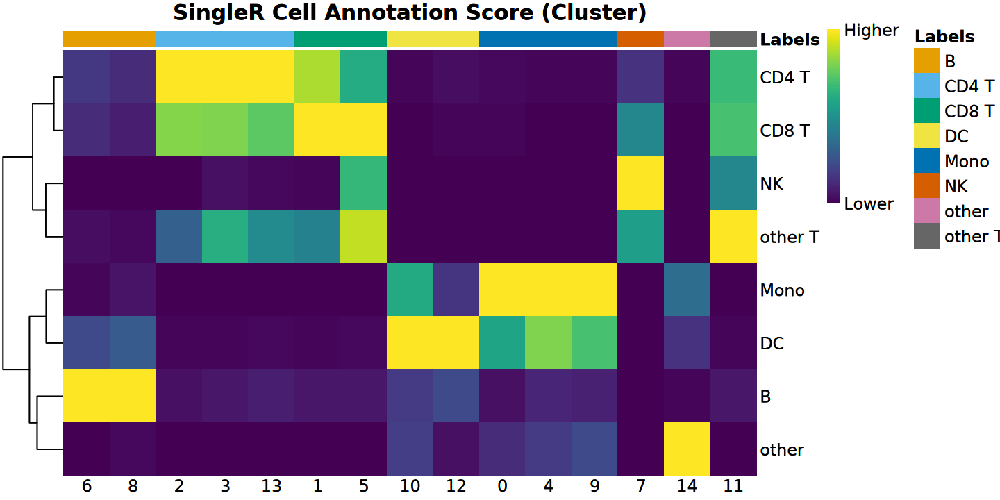

In [112]:
options(repr.plot.width = 12, repr.plot.height = 6)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [113]:
scrna$celltype.SingleR.l1 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

In [114]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l2, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

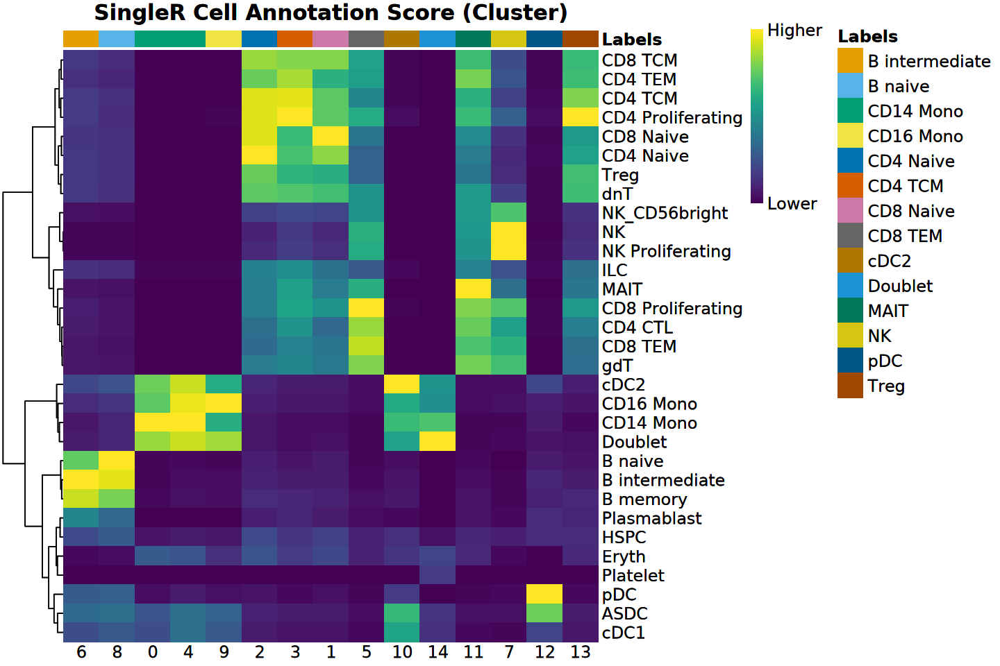

In [115]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [116]:
scrna$celltype.SingleR.l2 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

In [117]:
# SingleR performs the prediction of celltypes for each cluster
celltype.SingleR <- LayerData(
    scrna, assay = "RNA", layer = "data") |>
    SingleR(ref = ref_pbmc, labels = ref_pbmc$celltype.l3, 
            clusters = scrna$seurat_clusters,
            de.method = "wilcox")

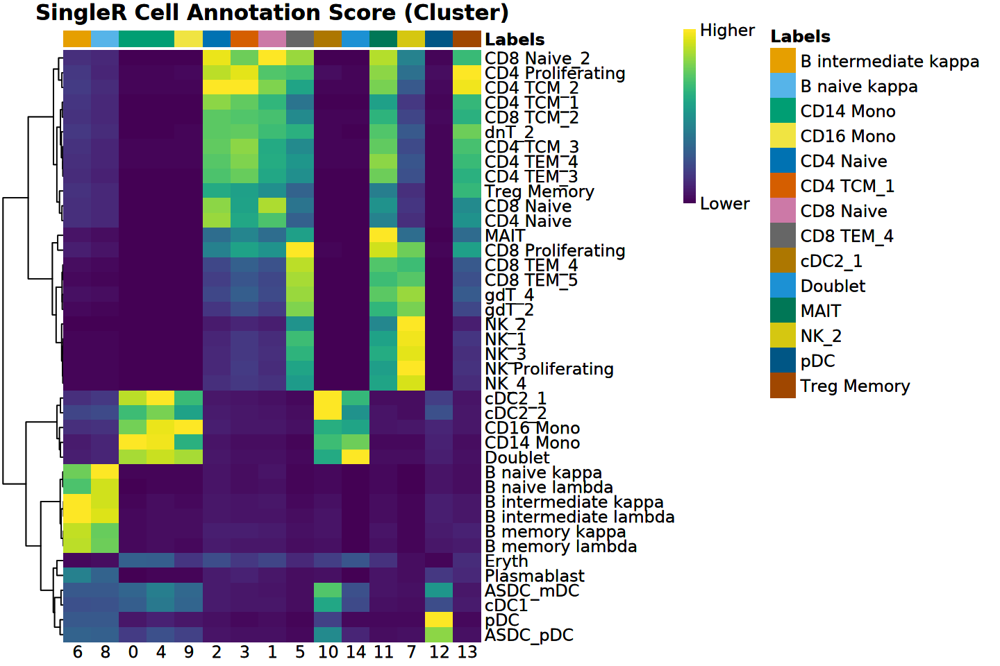

In [118]:
options(repr.plot.width = 12, repr.plot.height = 8)
plotScoreHeatmap(
    celltype.SingleR, show_colnames = TRUE, 
    main = "SingleR Cell Annotation Score (Cluster)",
    angle_col = 0, fontsize = 14)

In [119]:
scrna$celltype.SingleR.l3 <- 
    celltype.SingleR$labels[scrna$seurat_clusters]

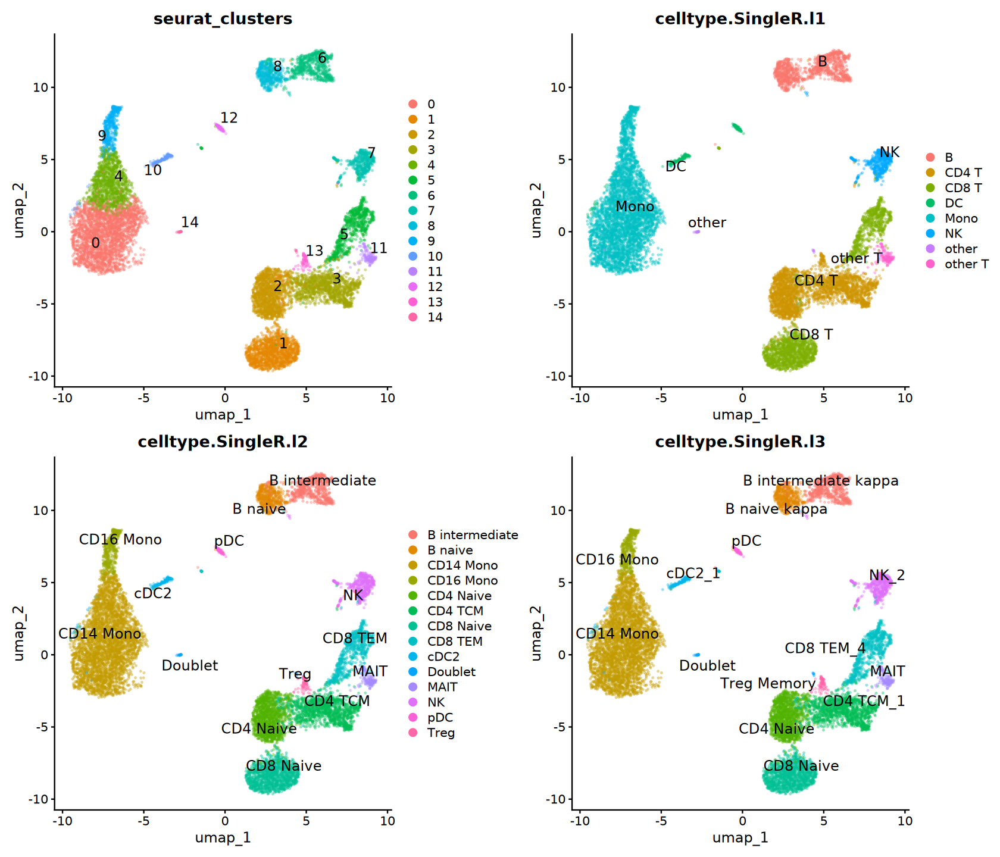

In [120]:
options(repr.plot.width = 14, repr.plot.height = 12)
DimPlot(scrna, reduction = "umap", 
        group.by = c("seurat_clusters", "celltype.SingleR.l1", 
                     "celltype.SingleR.l2", "celltype.SingleR.l3"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.3,  alpha = 0.3) &
    NoLegend()

## b). Manual

In [121]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [122]:
gene_list |> cat(sep = "\n")

cluster_0: "S100A12", "S100A8", "CYP1B1", "THBS1", "QPCT", "CRISPLD2", "STEAP4", "MCEMP1", "CLEC4D", "MARC1"
cluster_1: "CD8B", "CD8A", "KLRK1", "LINC02446", "NELL2", "LRRN3", "S100B", "PDE3B", "PASK", "SCGB3A1"
cluster_2: "CCR7", "LEF1", "FHIT", "TRABD2A", "CHRM3-AS2", "ADTRP", "TRAT1", "CD40LG", "FBLN5", "LINC01550"
cluster_3: "AQP3", "GPR183", "INPP4B", "CD40LG", "MAF", "TNFRSF4", "CD28", "GATA3", "SLAMF1", "ANK3"
cluster_4: "LGALS2", "CPVL", "APOBEC3A", "PEA15", "PID1", "SERPING1", "CLEC10A", "CXCL10", "SRC", "DHRS9"
cluster_5: "CCL5", "KLRG1", "TRGC2", "GZMH", "LINC01871", "FCRL6", "GZMK", "A2M-AS1", "LAG3", "EOMES"
cluster_6: "CD24", "TNFRSF13B", "FCRL2", "LINC01857", "IGHA1", "CPNE5", "IGHG1", "IGHG3", "LINC01781", "IGHG2"
cluster_7: "KLRF1", "SPON2", "AKR1C3", "SH2D1B", "NMUR1", "NCR1", "NCAM1", "IL18RAP", "LINC00299", "RNF165"
cluster_8: "TCL1A", "IGHD", "LINC00926", "FCER2", "FCRL1", "CD72", "COL19A1", "CD200", "PCDH9", "KCNG1"
cluster_9: "CDKN1C", "HES4", "FCGR3A", "CTSL", "

Picking joint bandwidth of 0.197

Picking joint bandwidth of 0.0175

Picking joint bandwidth of 0.0115

Picking joint bandwidth of 0.0557

Picking joint bandwidth of 0.0405

Picking joint bandwidth of 0.0911



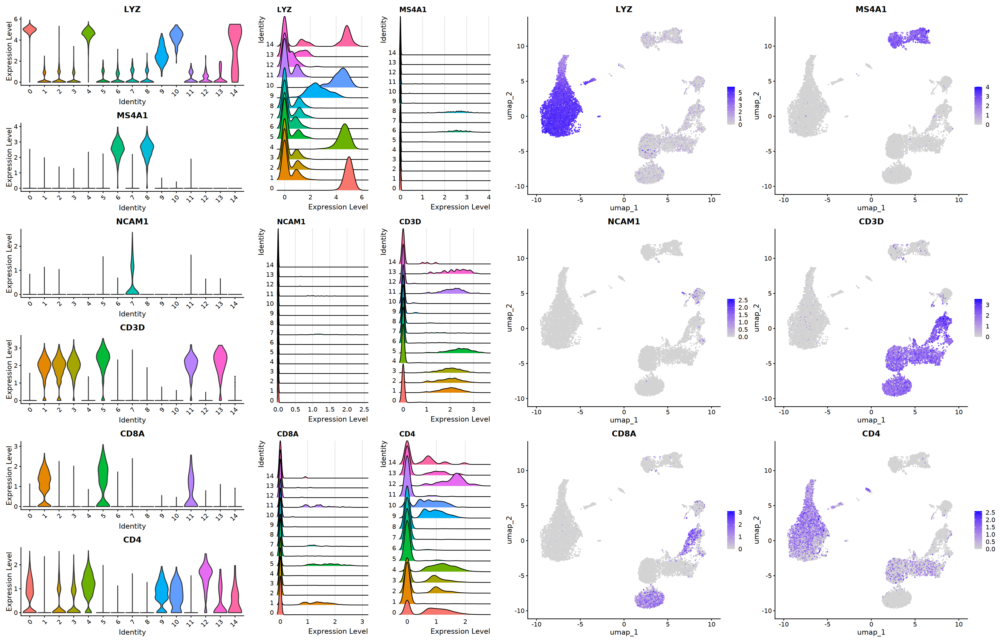

In [123]:
geneset <- c("LYZ", "MS4A1", "NCAM1", "CD3D", "CD8A", "CD4")
p1 <- VlnPlot(
    scrna, features = geneset, ncol = 1, pt.size = 0)
p2 <- RidgePlot(
    scrna, features = geneset, ncol = 2)
p3 <- FeaturePlot(
    scrna, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 28, repr.plot.height = 18)
plot_grid(p1, p2, p3, ncol = 3, rel_widths = c(1, 1, 2))

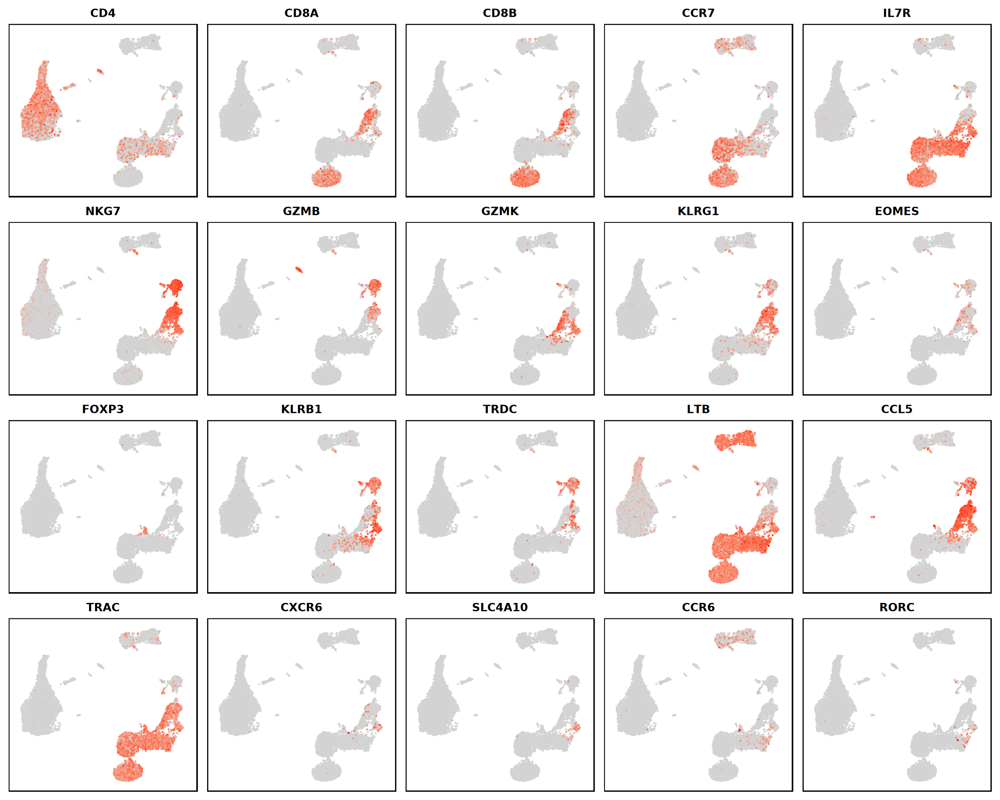

In [124]:
geneset <- c("CD4", "CD8A", "CD8B", "CCR7", "IL7R", 
             "NKG7", "GZMB", "GZMK", "KLRG1", "EOMES", 
             "FOXP3", "KLRB1", "TRDC", "LTB", "CCL5",
             "TRAC", "CXCR6", "SLC4A10", "CCR6", "RORC")

options(repr.plot.width = 20, repr.plot.height = 16)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

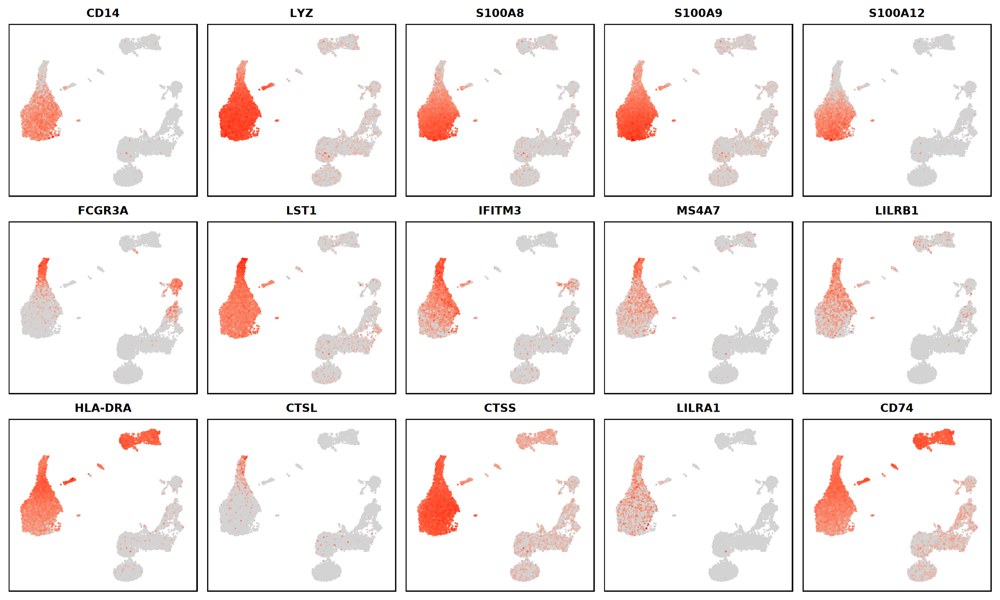

In [125]:
# Classical monocytes: "CD14", "LYZ", "S100A8", "S100A9", "S100A12"
# Non-classical monocytes: "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1"
# Intermediate monocytes: "CD14", "FCGR3A", "HLA-DRA", "HLA-DPB1", "CTSL", "CTSS", "LILRA1", "CD74"

geneset <- c("CD14", "LYZ", "S100A8", "S100A9", "S100A12",
             "FCGR3A", "LST1", "IFITM3", "MS4A7", "LILRB1",
             "HLA-DRA", "CTSL", "CTSS", "LILRA1", "CD74")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

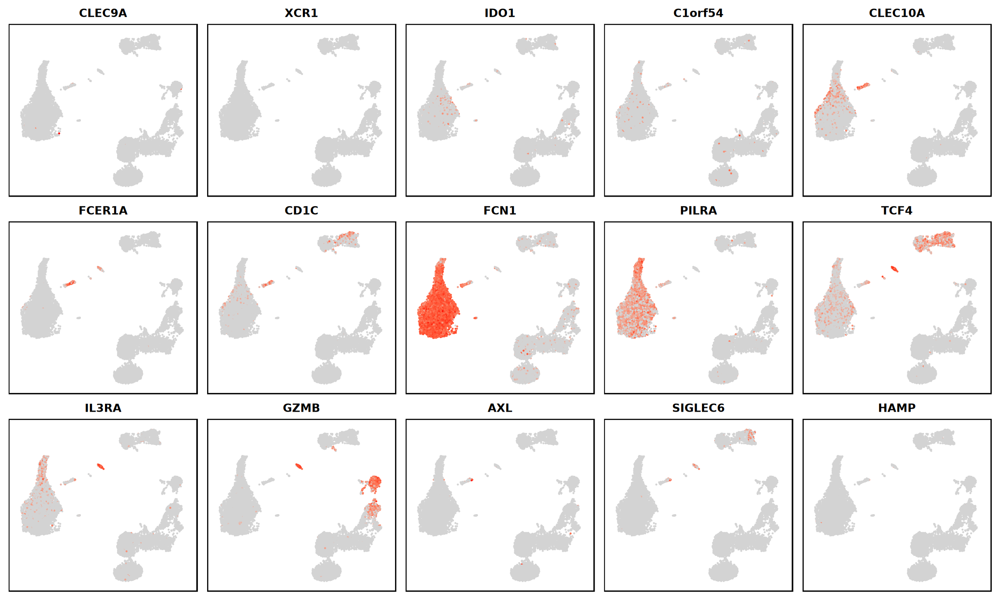

In [126]:
# cDC1: "CLEC9A", "XCR1", "IDO1", "C1orf54"
# cDC2: "CD1C", "FCN1", "PILRA"
# pDC: "GZMB", "TCF4", "IL3RA", "CLEC4C"
# ASDC: "AXL", "SIGLEC6", "HAMP"

geneset <- c("CLEC9A", "XCR1", "IDO1", "C1orf54",
             "CLEC10A", "FCER1A", "CD1C", "FCN1", "PILRA",
             "TCF4", "IL3RA", "GZMB",
             "AXL", "SIGLEC6", "HAMP")

options(repr.plot.width = 20, repr.plot.height = 12)
FeaturePlot(scrna, features = geneset, reduction = "umap", 
            cols = c("lightgrey", 'red'), ncol = 5) & 
    NoLegend() & NoAxes() &
    theme(panel.border = element_rect(color = "black", linewidth = 1))

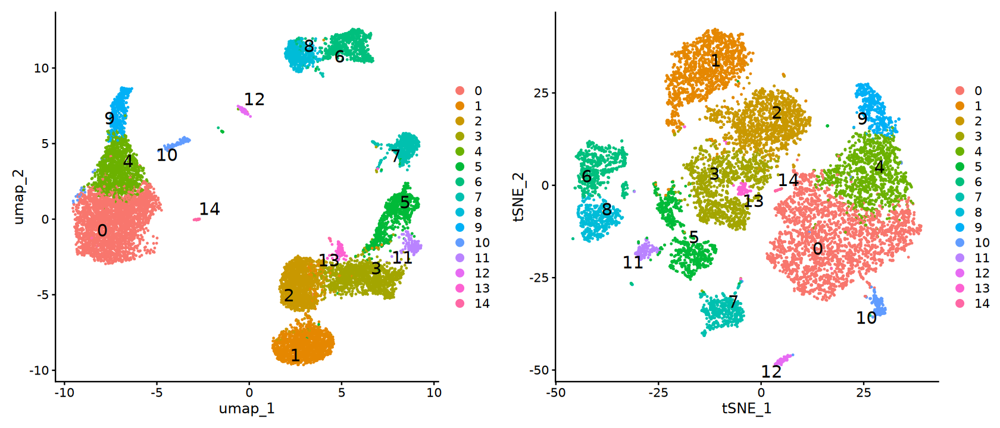

In [127]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 6, repel = TRUE)
p2 <- DimPlot(
    scrna, reduction = "tsne", label = TRUE, 
    label.size = 6, repel = TRUE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

In [128]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "Classical Monocytes", "1" = "Naïve/Memory CD8 T", "2" = "Naïve/Memory CD4 T",
    "3" = "Activated CD4 T", "4" = "Intermediate Monocytes", "5" = "Cytotoxic CD8 T",
    "6" = "Plasmablast", "7" = "NK Cells", "8" = "Naive B",
    "9" = "Non-classical Monocytes", "10" = "Dendritic Cells (cDC2)", "11" = "MAIT", 
    "12" = "pDC", "13" = "Treg", "14" = "Platelets")

# Mucosal-Associated Invariant T cells (MAIT)

In [129]:
scrna@meta.data$celltype <- 
    cluster2celltype[as.character(scrna$seurat_clusters)]

scrna <- RenameIdents(scrna, cluster2celltype)

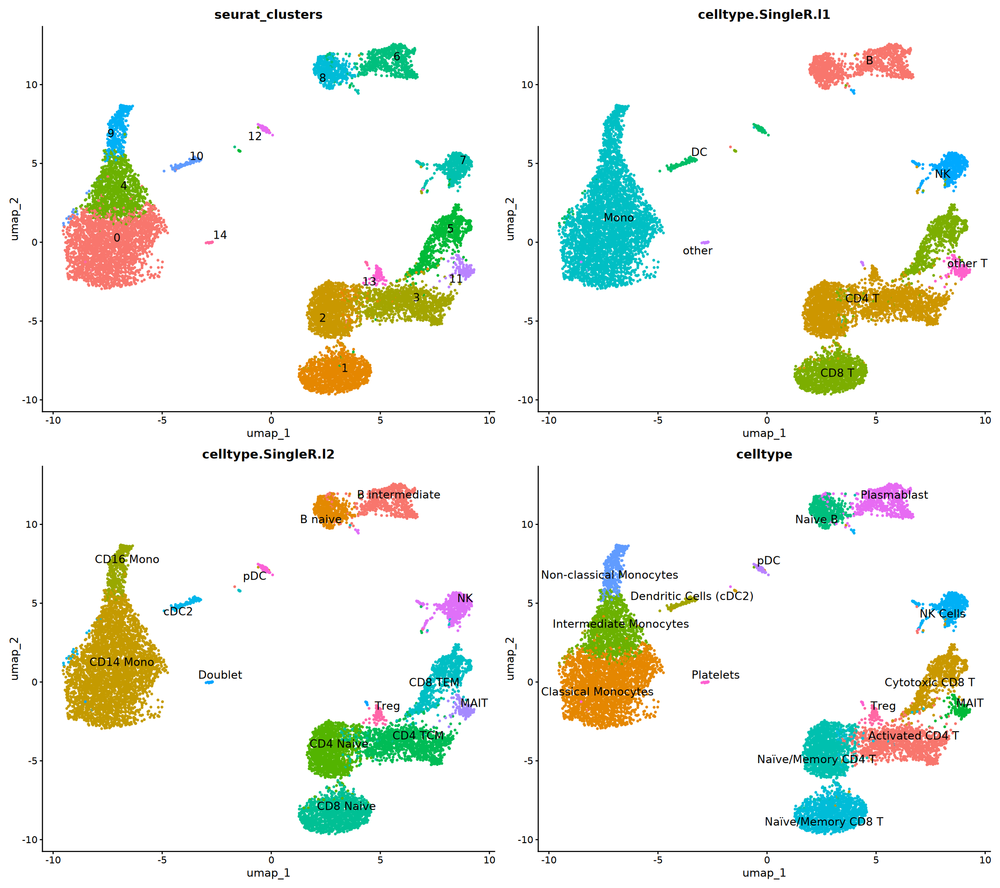

In [130]:
options(repr.plot.width = 18, repr.plot.height = 16)
DimPlot(scrna, reduction = "umap",
        group.by = c("seurat_clusters", "celltype.SingleR.l1", 
                     "celltype.SingleR.l2", "celltype"), 
        label = TRUE, repel = TRUE, label.size = 5, 
        pt.size = 0.5) & 
    NoLegend()

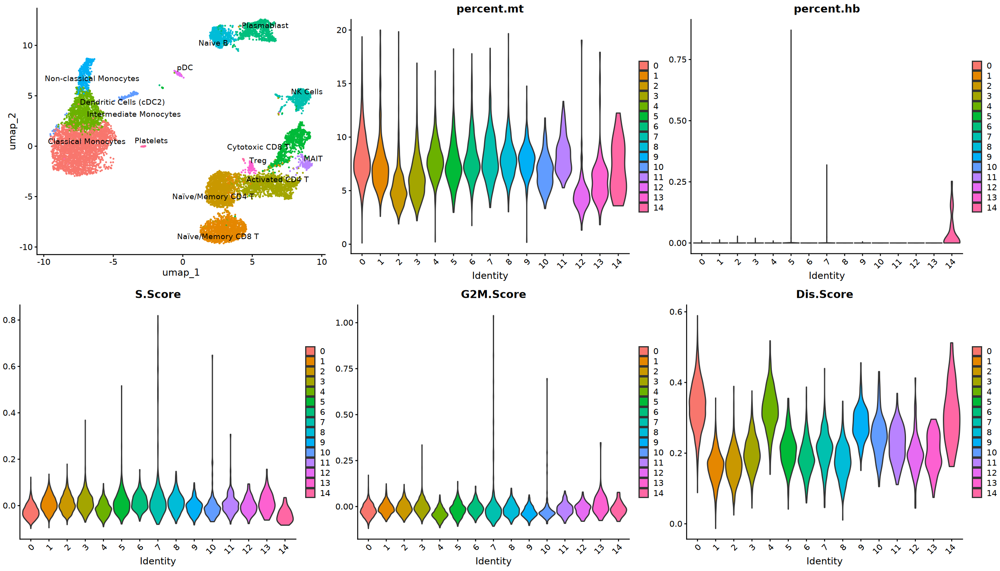

In [131]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- VlnPlot(
    scrna, features = c("percent.mt", "percent.hb"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)
p3 <- VlnPlot(
    scrna, features = c("S.Score", "G2M.Score", "Dis.Score"), 
    group.by = "seurat_clusters", pt.size = 0, combine = FALSE)

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2, p3), ncol = 3)

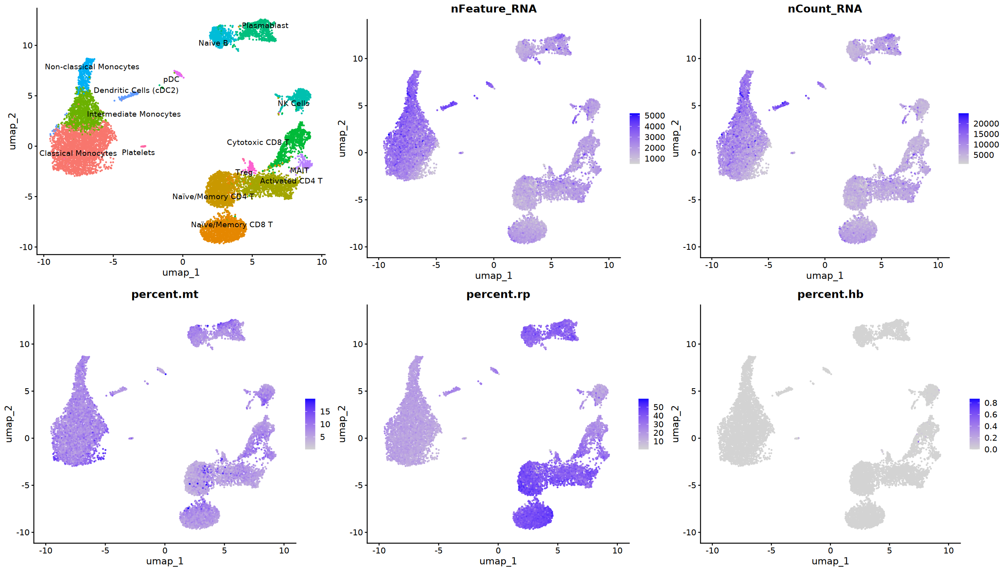

In [132]:
p1 <- DimPlot(
    scrna, reduction = "umap", label = TRUE, 
    label.size = 4, repel = TRUE) & NoLegend()
p2 <- FeaturePlot(
    scrna, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA", "percent.mt", 
                 "percent.rp", "percent.hb"))

options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = c(p1, p2), ncol = 3)

In [133]:
saveRDS(scrna, file.path(
    data_dir, "result", "s11_annotation_seurat_V5.rds"))